# Coffee Sales EDA


## **Business Questions**

1. How has monthly revenue trended since March 2024 ?
2. Which drink is the most popular and which does the most revenue ?
3. Which drink rarely ordered and could be dropped from menu ? 
4. When are the peak hours occurs ? and how's the difference between weekdays and weekends?

## **Import Libraries**

In [51]:
#import libraries
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## **Load Dataset**

In [52]:
#load dataset
df1 = pd.read_csv('data/index_1.csv')
df2 = pd.read_csv('data/index_2.csv')

df1.head()


,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte


In [53]:
print(df2.shape)
df2.head()

(262, 5)


,date,datetime,cash_type,money,coffee_name
0,2025-02-08,2025-02-08 14:26:04,cash,15.0,Tea
1,2025-02-08,2025-02-08 14:28:26,cash,15.0,Tea
2,2025-02-08,2025-02-08 14:33:04,card,20.0,Espresso
3,2025-02-08,2025-02-08 15:51:04,card,30.0,Chocolate with coffee
4,2025-02-08,2025-02-08 16:35:01,cash,27.0,Chocolate with milk


In [54]:
#merge both datasets
df = pd.concat([df1, df2], ignore_index=True)
df.head()

,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte


In [55]:
# Check data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3898 entries, 0 to 3897
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         3898 non-null   object 
 1   datetime     3898 non-null   object 
 2   cash_type    3898 non-null   object 
 3   card         3547 non-null   object 
 4   money        3898 non-null   float64
 5   coffee_name  3898 non-null   object 
dtypes: float64(1), object(5)
memory usage: 182.8+ KB


## **Data Cleaning**

In [56]:
# Check nulls and duplicates
print("Null values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

Null values:
 date             0
datetime         0
cash_type        0
card           351
money            0
coffee_name      0
dtype: int64

Duplicates: 2


In [57]:
df.loc[df["card"].isnull(), "cash_type"].value_counts()

cash_type
card    182
cash    169
Name: count, dtype: int64

In [58]:
print('df1 null values:\n', df1.isnull().sum())
print('df2 null values:\n', df2.isnull().sum())

df1 null values:
 date            0
datetime        0
cash_type       0
card           89
money           0
coffee_name     0
dtype: int64
df2 null values:
 date           0
datetime       0
cash_type      0
money          0
coffee_name    0
dtype: int64


In [59]:
df1.loc[df["card"].isnull(), "cash_type"].value_counts()

cash_type
cash    89
Name: count, dtype: int64

In [60]:
df2['cash_type'].value_counts()

cash_type
card    182
cash     80
Name: count, dtype: int64

most of missing values coming from transactions using cash and df2 since there is no card column.

In [61]:
#fix Datatype
df['datetime'] = pd.to_datetime(df['datetime'], format='mixed')

In [62]:
# remove duplicates
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

exact duplicates of transaction is dropped for data cleaning process.

In [63]:
#drop unused column
df = df.drop(columns=['card'])
df.head()

,date,datetime,cash_type,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,38.7,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,38.7,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,38.7,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,28.9,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,38.7,Latte


Card column dropped since the column is not used for EDA.

## **Exploratory Data Analysis**

### Get Additional Informations

#### Product Names

In [64]:
# get coffee names
coffee_names = df['coffee_name'].unique()
print('Number of Coffee Types:', len(coffee_names))
print('Coffee Names:', coffee_names)

Number of Coffee Types: 34
Coffee Names: ['Latte' 'Hot Chocolate' 'Americano' 'Americano with Milk' 'Cocoa'
 'Cortado' 'Espresso' 'Cappuccino' 'Tea' 'Chocolate with coffee'
 'Chocolate with milk' 'Coffee with Irish whiskey'
 'Irish whiskey with milk' 'Double Irish whiskey' 'Double espresso'
 'Americano with milk' 'Double espresso with milk'
 'Caramel with Irish whiskey' 'Super chocolate' 'Double vanilla'
 'Mochaccino' 'Caramel with chocolate' 'Irish whiskey' 'Caramel coffee'
 'Vanilla with Irish whiskey' 'Chocolate' 'Caramel with milk'
 'Coffee with chocolate' 'Irish with chocolate' 'Vanilla coffee'
 'Double ristretto' 'Hot milkshake' 'Double chocolate' 'Caramel']


In [65]:
# Coffee vs non-coffee sales count
# define coffees
coffee = ['coffee', 'espresso', 'latte', 'cappuccino', 'americano', 'mocha', 
          'macchiato', 'affogato', 'cortado', 'mochaccino', 'ristretto']
df['drink_type'] = df['coffee_name'].apply(lambda x: 'Coffee' if any(item in x.lower() for item in coffee) else 'Non-Coffee')

print('Number of Coffee Types:', df[df['drink_type'] == 'Coffee']['coffee_name'].nunique())
print('Number of Non-Coffee Types:', df[df['drink_type'] == 'Non-Coffee']['coffee_name'].nunique())
df.head()

Number of Coffee Types: 16
Number of Non-Coffee Types: 18


,date,datetime,cash_type,money,coffee_name,drink_type
0,2024-03-01,2024-03-01 10:15:50.520,card,38.7,Latte,Coffee
1,2024-03-01,2024-03-01 12:19:22.539,card,38.7,Hot Chocolate,Non-Coffee
2,2024-03-01,2024-03-01 12:20:18.089,card,38.7,Hot Chocolate,Non-Coffee
3,2024-03-01,2024-03-01 13:46:33.006,card,28.9,Americano,Coffee
4,2024-03-01,2024-03-01 13:48:14.626,card,38.7,Latte,Coffee


There are 34 unique drink types with 16 coffees and 18 non-coffees (Chocolate, Irish whiskey, Tea, etc.).

#### Get Year, Month, Day, Season, and Hour

In [66]:

# Get year from datetime
df['year'] = df['datetime'].dt.to_period('Y')

# Get month and season based on month
df['month'] = df['datetime'].dt.to_period('M')
seasons = {12: 'Winter', 1: 'Winter', 2: 'Winter',
           3: 'Spring', 4: 'Spring', 5: 'Spring',
           6: 'Summer', 7: 'Summer', 8: 'Summer',
           9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
df['season'] = df['datetime'].dt.month.map(seasons)

# Get day of the week from datetime
df['day_of_week'] = df['datetime'].dt.day_name()

# get hour from datetime
df['hour'] = df['datetime'].dt.hour

df.head()

,date,datetime,cash_type,money,coffee_name,drink_type,year,month,season,day_of_week,hour
0,2024-03-01,2024-03-01 10:15:50.520,card,38.7,Latte,Coffee,2024,2024-03,Spring,Friday,10
1,2024-03-01,2024-03-01 12:19:22.539,card,38.7,Hot Chocolate,Non-Coffee,2024,2024-03,Spring,Friday,12
2,2024-03-01,2024-03-01 12:20:18.089,card,38.7,Hot Chocolate,Non-Coffee,2024,2024-03,Spring,Friday,12
3,2024-03-01,2024-03-01 13:46:33.006,card,28.9,Americano,Coffee,2024,2024-03,Spring,Friday,13
4,2024-03-01,2024-03-01 13:48:14.626,card,38.7,Latte,Coffee,2024,2024-03,Spring,Friday,13


In [67]:
df.describe(include='all')

,date,datetime,cash_type,money,coffee_name,drink_type,year,month,season,day_of_week,hour
count,3896,3896,3896,3896.000000,3896,3896,3896,3896,3896,3896,3896.000000
unique,381,NaN,2,NaN,34,2,2,13,4,7,NaN
top,2025-02-21,NaN,card,NaN,Americano with Milk,Coffee,2024,2025-02,Spring,Tuesday,NaN
freq,34,NaN,3729,NaN,824,3260,2693,560,1111,604,NaN
mean,NaN,2024-10-11 04:33:58.325835520,NaN,31.383876,NaN,NaN,NaN,NaN,NaN,NaN,14.206622
min,NaN,2024-03-01 10:15:50.520000,NaN,15.000000,NaN,NaN,NaN,NaN,NaN,NaN,6.000000
25%,NaN,2024-07-16 17:42:58.480499968,NaN,27.920000,NaN,NaN,NaN,NaN,NaN,NaN,11.000000
50%,NaN,2024-10-15 20:45:18.520000,NaN,32.820000,NaN,NaN,NaN,NaN,NaN,NaN,14.000000
75%,NaN,2025-02-03 13:54:56.590499840,NaN,35.760000,NaN,NaN,NaN,NaN,NaN,NaN,18.000000
max,NaN,2025-03-23 21:23:11,NaN,40.000000,NaN,NaN,NaN,NaN,NaN,NaN,23.000000


There are 3896 transactions happened through March 1st 2024 to March 23rd 2025 with average sale amount of 31.38 UAH (Ukrainian Hryvnia), with most of transactions done using card with 3729 transactions.

In [68]:
# Total purchase by cash_type
total_purchases = df.groupby('cash_type')['money'].sum()
print(f'Total Sales: {df["money"].sum()} UAH')
print("Total sales by cash type:\n", total_purchases.map(lambda x: f"{x} UAH"))

Total Sales: 122271.57999999999 UAH
Total sales by cash type:
 cash_type
card    117114.58 UAH
cash       5157.0 UAH
Name: money, dtype: object


### Coffee Sales

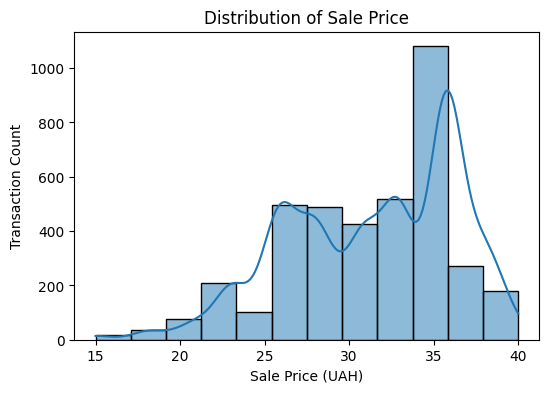

In [69]:
#Distribution of sale price
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x='money', bins=12, kde=True)
plt.title('Distribution of Sale Price')
plt.xlabel('Sale Price (UAH)')
plt.ylabel('Transaction Count')
plt.show()

In [70]:
fig = px.box(df, y='money', title='Boxplot of Money', width=500, height=400)
fig.update_layout(yaxis_title='Sale amount', margin=dict(l=40, r=20, t=40, b=20))
fig.show()

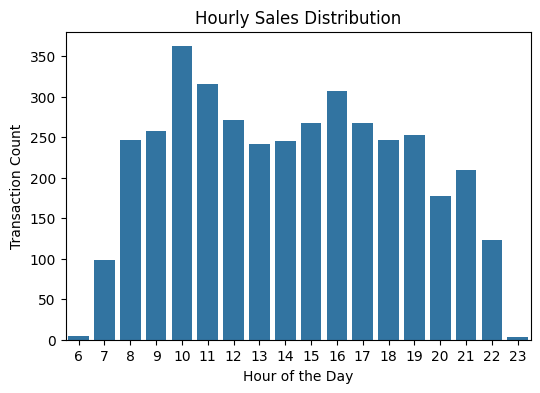

In [71]:
#Hourly sales distribution
hourly_sales=df.groupby(df["datetime"].dt.hour).size()
plt.figure(figsize=(6, 4))
sns.barplot(x=hourly_sales.index, y=hourly_sales.values)
plt.title('Hourly Sales Distribution')
plt.xlabel('Hour of the Day')
plt.ylabel('Transaction Count')
plt.show()

In [72]:
#Daily sales 
daily_sales = df.groupby(df['datetime'].dt.date)['money'].sum()
daily_sales = daily_sales.reindex(pd.date_range(start=daily_sales.index.min(), end=daily_sales.index.max(), freq='D'), fill_value=0)
fig = px.line(daily_sales, title='Daily Sales')
fig.update_layout(yaxis_title='Sales Amount', xaxis_title='Date')
fig.update_xaxes(tickformat="%b %Y")
fig.show()

In [73]:
# Average Daily sales
avg_daily_sales = daily_sales.rolling(7, min_periods=1).mean()
fig = px.line(avg_daily_sales, title='Average Daily Sales')
fig.update_layout(yaxis_title='Average Sales Amount', xaxis_title='Week Number')
fig.show()

In [ ]:
df['month'] = df['datetime'].dt.to_period('M').dt.to_timestamp()
monthly_sales = df.groupby('month')['money'].aggregate('sum').reset_index()
fig = px.bar(monthly_sales, x='month', y='money', title='Monthly Sales')
fig.update_layout(yaxis_title='Sales Amount', xaxis_title='Month', margin=dict(l=20, r=20, t=40, b=20))
fig.update_xaxes(tickmode='array', tickvals=monthly_sales['month'], tickformat='%b %Y')
fig.show()



In [75]:
# Coffee sales count with more than 10 sales
coffee_sale_count = df['coffee_name'].value_counts()
coffee_sale_count_filtered = coffee_sale_count[coffee_sale_count >= 10]
fig = px.bar(coffee_sale_count_filtered, x=coffee_sale_count_filtered.index, y=coffee_sale_count_filtered.values, title='Coffee Sales', width=800, height=400)
fig.update_layout(xaxis_tickangle=-45, yaxis_title='Total Sales', xaxis_title='Coffee Name', margin=dict(l=20, r=20, t=50, b=150))

In [76]:
# Bar chart for least sold coffee types with less than 10 sales
least_sold_coffee_count = coffee_sale_count[coffee_sale_count < 10]
fig = px.bar(least_sold_coffee_count, x=least_sold_coffee_count.index, y=least_sold_coffee_count.values, title='Least Sold Coffee Types') 
fig.update_layout(yaxis_title='Count', xaxis_title='Coffee Name', xaxis_tickangle=-45, margin=dict(l=20, r=20, t=50, b=150))
fig.show()